In [22]:
from dotenv import load_dotenv
load_dotenv()

True

In [23]:
from langgraph.graph import START,END,StateGraph
from langchain_groq import ChatGroq
from pydantic import BaseModel
from langgraph.types import interrupt,Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [24]:
llm=ChatGroq(model="openai/gpt-oss-20b")

In [25]:
class MailState(BaseModel):
    query:str=""
    draft:str=""
    human_feedback:str=""
    final_res:str=""
    

In [26]:
### defining the nodes
def draft_mail_node(state:MailState)->MailState:
    if state.human_feedback:
        draft=llm.invoke(f"""
            you have generated this mail :{state.draft}
            human feedback to apply :{state.human_feedback}
            rewrite this draft email for {state.query}
        """).content
    else:
        draft=llm.invoke(state.query).content
    state.draft=draft
    return state

def human_feedback_node(state:MailState)->MailState:
    feedback=interrupt({
        "draft_email":state.draft,
        "question":"Do you want ot continue or rewrite the mail"
    })
    fb=(feedback or  "").strip().lower()
    if fb in ("approved","ok","yes"):
        state.human_feedback=""
        return state
    else:
        state.human_feedback=feedback
        return state

def finalize_node(state:MailState)->MailState:
    print("email sent successfully")
    state.final_res=state.draft
    return state

def condition_routing(state:MailState)->Literal["draft","finalize"]:
    if state.human_feedback:
        return "draft"
    return "finalize"


In [27]:
graph_builder=StateGraph(MailState)
graph_builder.add_node("draft",draft_mail_node)
graph_builder.add_node("human_feedback",human_feedback_node)
graph_builder.add_node("finalize",finalize_node)

graph_builder.add_edge(START,"draft")
graph_builder.add_edge("draft","human_feedback")
graph_builder.add_conditional_edges("human_feedback",condition_routing)
graph_builder.add_edge("finalize",END)

graph=graph_builder.compile(checkpointer=InMemorySaver())

In [28]:
config={"configurable":{"thread_id":"1"}}                     

In [29]:
res=graph.invoke({"query":"i want to send a email for medical leave request"}, config=config)

In [30]:
print(res["draft"])
res

Below is a clean, professional template you can copy‑paste into your email client and then fill in the details that are specific to your situation. Feel free to tweak the wording to match your company’s tone or your personal style.

---

**Subject:** Medical Leave Request – [Your Full Name]

**Dear [Manager’s Name/HR Contact],**

I am writing to formally request medical leave due to a health issue that requires treatment and recovery time. My doctor has advised that I take the following period off from work:

- **Start date:** [MM/DD/YYYY]  
- **Estimated return date:** [MM/DD/YYYY] (I will keep you updated if this changes)

During my absence, I will ensure that all urgent tasks are delegated to [Colleague’s Name] and I will be reachable by email for any critical questions. I will also provide any additional documentation required (e.g., a doctor’s note, medical certificate) at the earliest convenience.

Please let me know if you need any further information or if there are forms I sho

{'query': 'i want to send a email for medical leave request',
 'draft': 'Below is a clean, professional template you can copy‑paste into your email client and then fill in the details that are specific to your situation. Feel free to tweak the wording to match your company’s tone or your personal style.\n\n---\n\n**Subject:** Medical Leave Request – [Your Full Name]\n\n**Dear [Manager’s Name/HR Contact],**\n\nI am writing to formally request medical leave due to a health issue that requires treatment and recovery time. My doctor has advised that I take the following period off from work:\n\n- **Start date:**\u202f[MM/DD/YYYY]  \n- **Estimated return date:**\u202f[MM/DD/YYYY] (I will keep you updated if this changes)\n\nDuring my absence, I will ensure that all urgent tasks are delegated to [Colleague’s Name] and I will be reachable by email for any critical questions. I will also provide any additional documentation required (e.g., a doctor’s note, medical certificate) at the earliest 

In [31]:
res=graph.invoke(Command(resume="i want to change the leave dates and new dates are 4th june to 7yh june and i want to remove the place holders and just say thankyou"),config=config)

In [32]:
print(res["draft"])
res

**Subject:** Medical Leave Request  

Dear Manager,

I am writing to request medical leave from **June 4, 2026 to June 7, 2026**, as advised by my doctor. I will keep you updated if the dates change.

I have briefed a colleague to handle urgent matters while I’m away and will remain reachable by email for any critical questions.

Please let me know if you need a doctor’s note or any additional information.

Thank you,


{'query': 'i want to send a email for medical leave request',
 'draft': '**Subject:** Medical Leave Request  \n\nDear Manager,\n\nI am writing to request medical leave from **June\u202f4,\u202f2026 to June\u202f7,\u202f2026**, as advised by my doctor. I will keep you updated if the dates change.\n\nI have briefed a colleague to handle urgent matters while I’m away and will remain reachable by email for any critical questions.\n\nPlease let me know if you need a doctor’s note or any additional information.\n\nThank you,',
 'human_feedback': 'i want to change the leave dates and new dates are 4th june to 7yh june and i want to remove the place holders and just say thankyou',
 'final_res': '',
 '__interrupt__': [Interrupt(value={'draft_email': '**Subject:** Medical Leave Request  \n\nDear Manager,\n\nI am writing to request medical leave from **June\u202f4,\u202f2026 to June\u202f7,\u202f2026**, as advised by my doctor. I will keep you updated if the dates change.\n\nI have briefed a coll

In [19]:
print(res["draft"])

In [14]:
res=graph.invoke(Command(resume="yes"),config=config)

email sent successfully


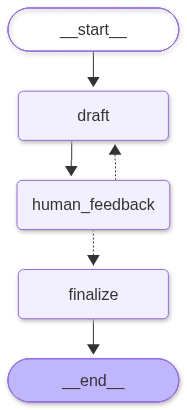

In [15]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [20]:
print(res["draft"])
